# RTDose module

This module contains functions to work with RT Dose, CT image and RT Structures in DICOM files.


## Dose volume histogram

In [4]:
from Dosepy import rtdose as rt

# Create an RTSet object and use load methods to read the DICOM files.
# Do not forget to change this to your file path :)
rtset = rt.RTSet()
rtset.load_ct_image("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/CT/")
rtset.load_dose("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RD.dcm")
rtset.load_structures("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RS_Esfera&Anillo.dcm")

Note: For now, Dosepy does not check associations between the given DICOM files (i.e. same patient for all files).

Print the name and roi number of each structure

In [5]:
print(rtset.print_rois())

{'BODY': 1, 'CouchSurface': 2, 'CouchInterior': 3, 'PTV_High': 4, 'NS_Ring': 5, 'PRV': 6, 'NS_Control': 7}


Create numpy arrays as masks for some structures.

In [6]:
ring = rtset.create_structure_mask(5)
ptv = rtset.create_structure_mask(4)
sphere_and_ring = rtset.create_structure_mask(7)

Resample dose distribution in CT voxels. For now, it uses lineal interpolation.

In [7]:
dose_in_ct = rtset.resample_dose_in_ct_positions()

Show dose distribution, structures and dose statistics

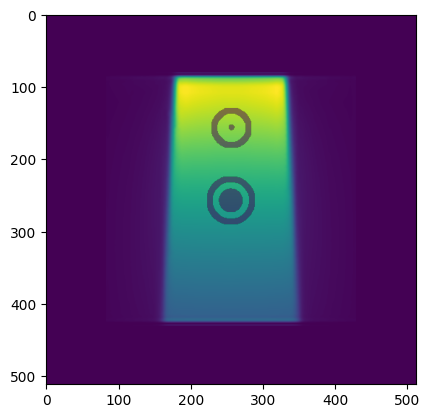

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import SimpleITK as sitk

# Dose as numpy array
dose_2D = sitk.GetArrayFromImage(dose_in_ct[:,:,40])

fig, ax = plt.subplots(1,1)
ax.imshow(dose_2D)

mx = np.ma.masked_array(sphere_and_ring, mask=~sphere_and_ring)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ptv, mask=~ptv)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ring, mask=~ring)
ax.imshow(mx[40,:,:], alpha=0.5)

## Validation

We have exported DICOM files (RD.dcm, RS.dcm and CT.dcm) from Eclipse V18.1.
A square filed, 10 cm x 10 cm, and a square virtual phantom 20 cm in size was used for dose calculation with AcurosXB_1811.

![Eclipse181](../assets/DoseInStructures.JPG)

In [9]:
dose_in_ct_array = sitk.GetArrayFromImage(dose_in_ct)
print("\nDose statistics in PTV_High")
print("\t\t\tDosepy\t\tEclipse")
print(f"\tMean dose: \t{round(np.mean(dose_in_ct_array[ptv]), 2)} Gy\t\t2.00 Gy.")
print(f"\tMin dose: \t{round(np.min(dose_in_ct_array[ptv]), 2)} Gy\t\t1.88 Gy.")
print(f"\tMax dose: \t{round(np.max(dose_in_ct_array[ptv]), 2)} Gy\t\t2.13 Gy.")
print("\nDose statistics in NS_Ring")
print("\t\t\tDosepy\t\tEclipse")
print(f"\tMean dose: \t{round(np.mean(dose_in_ct_array[ring]), 2)} Gy\t\t2.00 Gy.")
print(f"\tMin dose: \t{round(np.min(dose_in_ct_array[ring]), 2)} Gy\t\t1.77 Gy.")
print(f"\tMax dose: \t{round(np.max(dose_in_ct_array[ring]), 2)} Gy\t\t2.26 Gy.")
print("\nDose statistics in NS_Control")
print("\t\t\tDosepy\t\tEclipse")
print(f"\tMean dose: \t{round(np.mean(dose_in_ct_array[sphere_and_ring]), 2)} Gy\t\t2.85 Gy.")
print(f"\tMin dose: \t{round(np.min(dose_in_ct_array[sphere_and_ring]), 2)} Gy\t\t2.61 Gy.")
print(f"\tMax dose: \t{round(np.max(dose_in_ct_array[sphere_and_ring]), 2)} Gy\t\t3.09 Gy.")


Dose statistics in PTV_High
			Dosepy		Eclipse
	Mean dose: 	2.0 Gy		2.00 Gy.
	Min dose: 	1.88 Gy		1.88 Gy.
	Max dose: 	2.13 Gy		2.13 Gy.

Dose statistics in NS_Ring
			Dosepy		Eclipse
	Mean dose: 	2.0 Gy		2.00 Gy.
	Min dose: 	1.77 Gy		1.77 Gy.
	Max dose: 	2.25 Gy		2.26 Gy.

Dose statistics in NS_Control
			Dosepy		Eclipse
	Mean dose: 	2.85 Gy		2.85 Gy.
	Min dose: 	2.6 Gy		2.61 Gy.
	Max dose: 	3.1 Gy		3.09 Gy.


In [7]:
rt.plot_dvh(dose_in_ct_array[ptv])

 To get **Dx**: minimum dose received by the hottest sub volume x
(e.g., D20%[Gy])

In [10]:
import numpy as np

# Volume as percentage
volume = 20  

# Minimum dose to the hottest 20% of the volume
D20 = np.percentile(dose_in_ct_array[ptv], 100 - volume)

# Compare with TPS (Eclipse v16)
reference = 2.05  # Dose reported by the TPS
difference = 100 * (D20 - reference) / reference  # Percentage

print("PTV_High")
print(f"D20% (Dosepy) = {D20:.2f} Gy")
print(f"D20% (Reference TPS) = {reference:.2f} Gy")
print(f"Difference = {difference:.2f} %")

PTV_High
D20% (Dosepy) = 2.05 Gy
D20% (Reference TPS) = 2.05 Gy
Difference = 0.24 %


### Dose object

The RTDose module leverages the SimpleITK library, utilizing the **Image** class to represent dose distributions. This allows users to access the full suite of methods and functionalities provided by SimpleITK for image processing and analysis. For example, you can easily manipulate, resample, or visualize dose distributions using familiar SimpleITK operations.

In [13]:
# Basic image attributes

print(f"DICOM origin: {dose_in_ct.GetOrigin()}")
print(f"Size: {dose_in_ct.GetSize()}")
print(f"Spacing: {dose_in_ct.GetSpacing()}")
print(f"Direction: {dose_in_ct.GetDirection()}\n")

DICOM origin: (-149.70703125, -149.70703125, -102.5)
Size: (512, 512, 83)
Spacing: (0.5859375, 0.5859375, 2.5)
Direction: (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)



For more information on the SimpleITK Image class, refer to the [SimpleITK documentation](https://insightsoftwareconsortium.github.io/SimpleITK-Notebooks/Python_html/03_Image_Details.html).

### Conversion to numpy array and plotting:

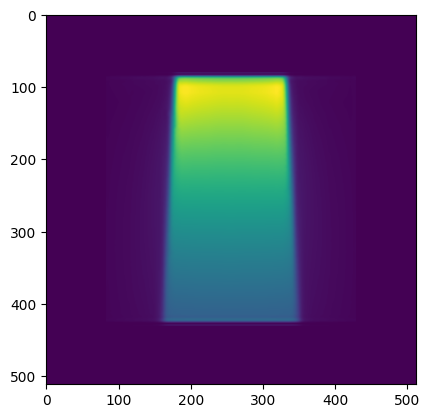

In [14]:

import SimpleITK as sitk

plt.imshow(sitk.GetArrayFromImage(dose_in_ct[:, :, 40]))

### DICOM Reference Coordinate System

The DICOM standard defines a Reference Coordinate System (RCS) which is oriented with respect to the patient. The RCS allows us to measure the position and orientation of an image relative to the patient.

![DICOMCoordinateReferenceSystem](../assets/DICOM_Coordinate_Reference_System.png)

* **The positive X direction** points to the patient's left.
* **The positive Y direction** points towards the patient's back (anterior to posterior).
* **The positive Z direction** points towards the patient's head (inferior to superior).

## DICOM Registration

In [27]:
import pydicom

path_to_registration_file = "/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/RE.dcm"
re = pydicom.dcmread(path_to_registration_file)

# Check 
print(re)
#print(re.RegistrationSequence[-1])
#print(re.RegistrationSequence[-1].MatrixRegistrationSequence[-1])
#print(re.RegistrationSequence[-1].MatrixRegistrationSequence[-1].MatrixSequence[-1])
#re.RegistrationSequence[-1].MatrixRegistrationSequence[-1].MatrixSequence[-1].FrameOfReferenceTransformationMatrix

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 190
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Spatial Registration Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.246.352.205.4674913873122172933.13220929552096385428
(0002,0010) Transfer Syntax UID                 UI: Implicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.246.352.70.2.1.160.3
(0002,0013) Implementation Version Name         SH: 'DCIE 18.1'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 192'
(0008,0012) Instance Creation Date              DA: '20261122'
(0008,0013) Instance Creation Time              TM: '062614'
(0008,0016) SOP Class UID                       UI: Spatial Registration Storage
(0008,0018) SOP Instance UID                    UI: 1.2.246.352.205.4674913873122172933.1322092955209

In [ ]:
# Adapted from https://github.com/brianmanderson/RegisteringImages/blob/main/src/RegisterImages/WithDicomReg.py
def register_images_with_dicom_reg(fixed_image: sitk.Image, moving_image: sitk.Image, dicom_registration=None,
                                   min_value=-1000, method=sitk.sitkLinear):
    """
    :param fixed_image: The fixed image
    :param moving_image: The moving image
    :param dicom_registration: the DICOM Registration file, if registration is from CTT 8 to 11, fixed is CT 11, moving is CT 8, 
    :param min_value: Value to put as background in resampled image
    :param method: interpolating method, recommend sitk.sitkLinear for images and sitk.sitkNearestNeighbor for masks
    :return:
    """
    affine_transform = sitk.AffineTransform(3)
    if dicom_registration is not None:
        if type(dicom_registration) is pydicom.dataset.FileDataset:
            registration_matrix = np.asarray(dicom_registration.RegistrationSequence[-1].MatrixRegistrationSequence[-1].
                                             MatrixSequence[-1].FrameOfReferenceTransformationMatrix).reshape((4, 4))
        else:
            print("Assuming the dicom_registration passed is a registration matrix")
            registration_matrix = np.asarray(dicom_registration).reshape((4, 4))
        #registration_matrix = np.linalg.inv(registration_matrix)
        affine_transform.SetMatrix(registration_matrix[:3, :3].ravel())
        affine_transform.SetTranslation(registration_matrix[:3, -1])

    moving_resampled = sitk.Resample(moving_image, fixed_image, affine_transform, method, min_value,
                                     moving_image.GetPixelID())
    return moving_resampled

In [62]:
rt_fixed = rt.RTSet()
rt_moving = rt.RTSet()

rt_fixed.load_ct_image("/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/Fixed/CT/")
rt_moving.load_ct_image("/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/Moving/CT/")

ct_moving_resampled = register_images_with_dicom_reg(rt_fixed.ct, rt_moving.ct, re)


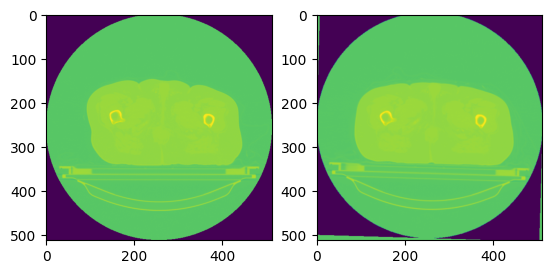

In [63]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,2)
ax[0].imshow(sitk.GetArrayFromImage(rt_fixed.ct[:, :, 50]))
ax[1].imshow(sitk.GetArrayFromImage(ct_moving_resampled[:, :, 50]))


In [64]:
rt_fixed.load_dose("/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/Fixed/RD.dcm")
rt_fixed.load_structures("/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/Fixed/RS.dcm")

rt_moving.load_dose("/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/Moving/RD.dcm")
rt_moving.load_structures("/home/luis/Documentos/DosepyEQD2/RT_module/ID294_Recto/Moving/RS.dcm")

In [65]:
dose_resampled = register_images_with_dicom_reg(rt_fixed.dose, rt_moving.dose, re, min_value=0)

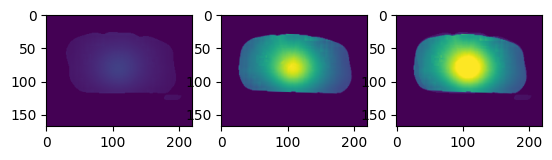

In [73]:
d1 = sitk.GetArrayFromImage(rt_fixed.dose)
d2 = sitk.GetArrayFromImage(dose_resampled)

d_total = d1 + d2
#plt.imshow(sitk.GetArrayFromImage(rt_moving.dose[120,:,:]))
fig, ax = plt.subplots(1,3)
ax[0].imshow(sitk.GetArrayFromImage(rt_fixed.dose[:, :, 50]), vmax=3)
ax[1].imshow(sitk.GetArrayFromImage(dose_resampled[:, :, 50]), vmax=3)
ax[2].imshow(d_total[50,:,:], vmax=3)


## EQD2 conversion

In [ ]:
import Dosepy.rtdose as rt

# Load the DICOM files
dose_map = rt.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")
structure_set = rt.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

rt.eqd2(
    dose_distribution = dose_map,
    fractions = 1,
    structures = structure_set,
    alpha_beta = {
        "PTV_High": 10,
    }
)

In [ ]:
# Read CT image
# Read dose distribution 
# Read structure set

# Resample dose distribution on CT points

# Create mask on CT image shape and resolution
# Get doses in the mask
# 
import SimpleITK as sitk
from Dosepy import rtdose as rt

ct = rt.load_ct_image("/media/luis/TOMO/Dosepy/Hombro20en1/CT/")
dose_map = rt.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")
structure_set = rt.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

In [ ]:
ct.GetOrigin()

In [ ]:
dose_map.GetOrigin()

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,2)
ax[0].imshow(sitk.GetArrayFromImage(dose_map[:, :, 30]))
z_point = dose_map.TransformContinuousIndexToPhysicalPoint((0,0,30))[2]

z_index = interpolated_dose.TransformPhysicalPointToContinuousIndex((0,0,z_point))[2]
print(z_index)
ax[1].imshow(sitk.GetArrayFromImage(interpolated_dose[:, :, int(z_index)]))
print(z_point)

In [ ]:
plt.imshow(sitk.GetArrayFromImage(ct[:, :, 30]))

In [ ]:
plt.imshow(sitk.GetArrayFromImage(interpolated_dose[:, :, 60]))

z_index = interpolated_dose.TransformPhysicalPointToContinuousIndex((0,0,z_point))[2]
print(f"{z_index=}")

# Get physical position in Z direction, based on index
z_origin = interpolated_dose.GetOrigin()[2]
z_spacing = interpolated_dose.GetSpacing()[2]

z_position = z_origin + z_spacing*30
print("Manual calculation:")
print(z_position)

print(interpolated_dose.TransformIndexToPhysicalPoint((0,0,30)))


In [ ]:
ct[:,:,0].GetSpacing()
ct[:,:,0].GetSize()

interpolated_dose = sitk.Resample(
        dose_map,
        ct,
        sitk.Transform(3, sitk.sitkIdentity),
        sitk.sitkLinear,
    )

In [ ]:
print(dose_map.GetSize())
print(interpolated_dose.GetSize())


In [ ]:
# Get the vertices of the structure "PTV_High"
ptv_coordinates = structure_set.get_coordinates("PTV_High")

dose_in_structure = []
i = 0
for slice_coordinates in ptv_coordinates:
    # Check that each slice_coordinates has a constant z coordinate
    if not len(set(slice_coordinates[:, 2])) == 1:
        raise ValueError("Each slice_coordinates must have a constant z coordinate.")
    
    z_coordinate = slice_coordinates[0, 2]

    dose_2D = rt.get_axial_dose_plane(interpolated_dose, z_coordinate)

    dose_in_structure_in_slice = rt.get_dose_in_structure_by_plane(dose_2D, slice_coordinates)

    dose_in_structure.extend(dose_in_structure_in_slice)
    print(i)

# Structure resolution

In [ ]:
ptv_coordinates[0]

In [ ]:
len(ptv_coordinates)

# Show CT and PTV structure

In [ ]:
z_physical_for_structure = 1
z_ct_index_ptv = ct.TransformPhysicalPointToContinuousIndex((0, 0, z_physical_for_structure))[2]
print(z_ct_index_ptv)

# Create the mask
ptv_mask = rt.get_2D_mask_by_coordinates_and_image_shape(ptv_coordinates[0], ct[:,:,0])
ptv_mask_ma = np.ma.masked_where(ptv_mask == 0, ptv_mask)
print(ptv_mask_ma.size)

fig, ax = plt.subplots(1,1)
ax.imshow(sitk.GetArrayFromImage(ct[:, :, int(z_ct_index_ptv)]), cmap="gray")
ax.imshow(ptv_mask_ma, alpha=0.5)


In [ ]:
import numpy as np

# Volume as percentage
volume = 20  

# Minimum dose to the hottest 20% of the volume
D20 = np.percentile(dose_in_structure, 100 - volume, method="weibull")

# Compare with TPS (Eclipse v16)
reference = 3.55  # Dose reported by the TPS
difference = 100 * (D20 - reference) / reference  # Percentage

print("PTV_High")
print(f"D20% (Dosepy) = {D20:.2f} Gy")
print(f"D20% (Reference TPS) = {reference:.2f} Gy")
print(f"Difference = {difference:.2f} %")

In [ ]:
for slice_coodinate in body_coordinates:
    #print(slice_coodinate[2])
    pass

ct.GetOrigin()
ct.GetSpacing()

In [ ]:
from Dosepy import rtdose

print(structure_set.get_names())
couch_contour = structure_set.get_roi_contour(4)
#print(couch_contour)
print(couch_contour.ContourSequence)

types = set()
for contour_sequence in couch_contour.ContourSequence:
    #print(contour)
    print(contour_sequence.ContourGeometricType)
    types.add(contour_sequence.ContourGeometricType)

print(len(types))

ct.GetSize()

rt_set = rtdose.RTSet()
rt_set.load_ct_image()

In [ ]:
from Dosepy import rtdose as rt

rtset = rt.RTSet()
rtset.load_ct_image("/media/luis/TOMO/Dosepy/Hombro20en1/CT/")
rtset.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")
rtset.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

ptv_mask = rtset.create_structure_mask(2)
print(rtset.ss.get_names())

In [ ]:
import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

fig, ax = plt.subplots(1,1)
ax.imshow(sitk.GetArrayFromImage(rtset.ct[:, :, 60]), cmap="gray")
mx = np.ma.masked_array(ptv_mask, mask=~ptv_mask)
ax.imshow(mx[60,:,:], alpha=0.5)

#ax.imshow(sitk.LabelOverlay(rtset.ct[:,:,25], ptv_mask[:,:,25]))
rtset.ct.TransformPhysicalPointToIndex((0,0,1))
#plt.hist(ptv_mask.flatten())

In [ ]:
path_to_ring_plan = "/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/"

from Dosepy import rtdose as rt

rtset = rt.RTSet()
rtset.load_ct_image("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/CT/")
rtset.load_dose("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RD.dcm")
rtset.load_structures("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RS_Esfera&Anillo.dcm")

print(rtset.ss.get_names())

ring = rtset.create_structure_mask(5)
ptv = rtset.create_structure_mask(4)
esfera_anillo = rtset.create_structure_mask(7)

import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

fig, ax = plt.subplots(1,1)
#ax.imshow(sitk.GetArrayFromImage(rtset.ct[:, :, 40]), cmap="gray")
mx = np.ma.masked_array(esfera_anillo, mask=~esfera_anillo)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ptv, mask=~ptv)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ring, mask=~ring)
ax.imshow(mx[40,:,:], alpha=0.5)
#ax.imshow(sitk.LabelOverlay(rtset.ct[:,:,25], ptv_mask[:,:,25]))
print(rtset.ct.TransformPhysicalPointToIndex((0,0,0)))

sitk.GetArrayFromImage(rtset.ct[:, :, 40])


In [ ]:
dose_in_ct = rtset.resample_dose_in_ct_positions()
dose_2D = sitk.GetArrayFromImage(dose_in_ct[:,:,40])
fig, ax = plt.subplots(1,1)
ax.imshow(dose_2D)
mx = np.ma.masked_array(esfera_anillo, mask=~esfera_anillo)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ptv, mask=~ptv)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ring, mask=~ring)
ax.imshow(mx[40,:,:], alpha=0.5)

In [ ]:
dose_in_ct_array = sitk.GetArrayFromImage(dose_in_ct)
print(f"Mean dose in PTV_High: {np.mean(dose_in_ct_array[ptv])}")
print(f"Min dose in PTV: {np.min(dose_in_ct_array[ptv])}")
print(f"Min dose in PTV: {np.max(dose_in_ct_array[ptv])}")

print(f"Mean dose in Ring: {np.mean(dose_in_ct_array[ring])}")
print(f"Min dose in Ring: {np.min(dose_in_ct_array[ring])}")
print(f"Min dose in Ring: {np.max(dose_in_ct_array[ring])}")